In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os

In [2]:
path = "../data"

calendar = pd.read_csv(os.path.join(path, "calendar.csv"))
selling_prices = pd.read_csv(os.path.join(path, "sell_prices.csv"))
# sample_submission = pd.read_csv(os.path.join(path, "sample_submission.csv"))
sales = pd.read_csv(os.path.join(path, "sales_train_evaluation.csv"))

In [3]:
print(round(calendar.memory_usage(deep=True).sum()/(1024**2),2))
print(round(selling_prices.memory_usage(deep=True).sum()/(1024**2),2))
print(round(sales.memory_usage(deep=True).sum()/(1024**2),2))

0.72
957.52
463.29


In [4]:
# disater = pd.read_csv(os.path.join(path, "us_disasters_m5.csv")).head(500)
# disater.head(5)

In [5]:
from sklearn.preprocessing import OrdinalEncoder

def prep_calendar(df):
    df = df.drop(["date", "weekday", "event_type_1", "event_type_2"], axis=1)
    df = df.assign(d = df.d.str[2:].astype(int))
    to_ordinal = ["event_name_1", "event_name_2"] 
    df[to_ordinal] = df[to_ordinal].fillna("1")
    df[to_ordinal] = OrdinalEncoder(dtype="int").fit_transform(df[to_ordinal]) + 1
    to_int8 = ["wday", "month", "snap_CA", "snap_TX", "snap_WI"] + to_ordinal
    df[to_int8] = df[to_int8].astype("int8")
    
    return df

calendar = prep_calendar(calendar)
calendar.head()

,wm_yr_wk,wday,month,year,d,event_name_1,event_name_2,snap_CA,snap_TX,snap_WI
0,11101,1,1,2011,1,1,1,0,0,0
1,11101,2,1,2011,2,1,1,0,0,0
2,11101,3,1,2011,3,1,1,0,0,0
3,11101,4,2,2011,4,1,1,1,1,0
4,11101,5,2,2011,5,1,1,1,0,1


In [6]:
def downcast(df):
    cols = df.dtypes.index.tolist()
    types = df.dtypes.values.tolist()
    
    for i, t in enumerate(types):
        col = cols[i]
        if 'int' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)

        elif 'float' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            # ⚠️ Không dùng float16 vì không lưu được trong Parquet
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)

        elif str(t) == 'object':
            if col == 'date':
                df[col] = pd.to_datetime(df[col], format='%Y-%m-%d')
            else:
                df[col] = df[col].astype('category')
    
    return df

In [7]:
# Calculate memory usage before running the function
memory_before = {
    'calendar': calendar.memory_usage(deep=True).sum(),
    'sales': sales.memory_usage(deep=True).sum(),
    'prices': selling_prices.memory_usage(deep=True).sum()
}

sales = downcast(sales)
prices = downcast(selling_prices)
calendar = downcast(calendar)

memory_after = {
    'calendar': calendar.memory_usage(deep=True).sum(),
    'sales': sales.memory_usage(deep=True).sum(),
    'prices': prices.memory_usage(deep=True).sum()
}

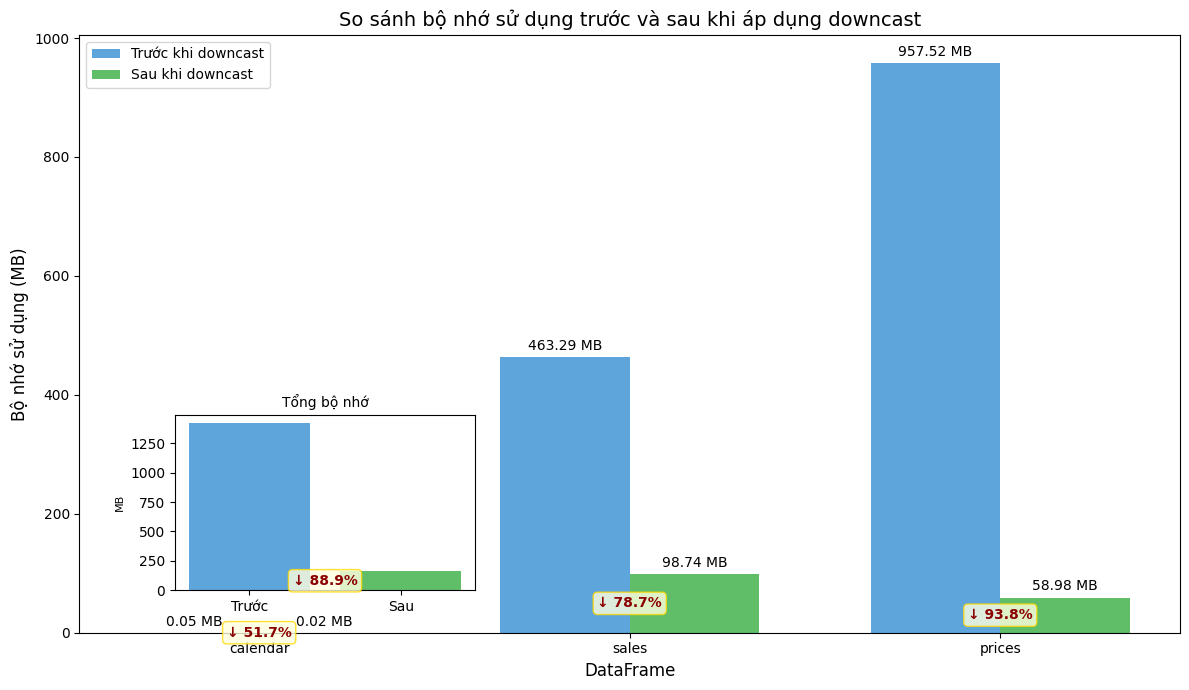


Thông tin chi tiết về bộ nhớ sử dụng:
DataFrame  Trước (MB)      Sau (MB)        Giảm (MB)       Giảm (%)  
----------------------------------------------------------------------
calendar   0.05            0.02            0.03            51.7      
sales      463.29          98.74           364.56          78.7      
prices     957.52          58.98           898.54          93.8      
----------------------------------------------------------------------
TỔNG       1420.86         157.75          1263.12         88.9      


In [8]:
def plot_memory_comparison(memory_before, memory_after):
    """
    Vẽ biểu đồ so sánh bộ nhớ sử dụng trước và sau khi tối ưu hóa.
    
    Parameters:
    -----------
    memory_before : dict
        Dictionary chứa bộ nhớ sử dụng trước khi tối ưu hóa.
    memory_after : dict
        Dictionary chứa bộ nhớ sử dụng sau khi tối ưu hóa.
    """
    import matplotlib.pyplot as plt
    import numpy as np
    
    # Lấy tên của các DataFrame
    df_names = list(memory_before.keys())
    
    # Tính toán giá trị bộ nhớ ở MB
    before_mb = [memory_before[name] / (1024 * 1024) for name in df_names]
    after_mb = [memory_after[name] / (1024 * 1024) for name in df_names]
    
    # Tính phần trăm giảm bộ nhớ
    reduction_pct = [(memory_before[name] - memory_after[name]) / memory_before[name] * 100 for name in df_names]
    
    # Thiết lập vị trí của các cột
    x = np.arange(len(df_names))
    width = 0.35
    
    # Tạo biểu đồ
    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Vẽ cột
    rects1 = ax.bar(x - width/2, before_mb, width, label='Trước khi downcast', color='#5DA5DA')
    rects2 = ax.bar(x + width/2, after_mb, width, label='Sau khi downcast', color='#60BD68')
    
    # Thêm nhãn, tiêu đề và các thông tin khác
    ax.set_xlabel('DataFrame', fontsize=12)
    ax.set_ylabel('Bộ nhớ sử dụng (MB)', fontsize=12)
    ax.set_title('So sánh bộ nhớ sử dụng trước và sau khi áp dụng downcast', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(df_names)
    ax.legend()
    
    # Thêm giá trị lên mỗi cột
    def add_labels(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.2f} MB',
                         xy=(rect.get_x() + rect.get_width() / 2, height),
                         xytext=(0, 3),  # 3 points vertical offset
                         textcoords="offset points",
                         ha='center', va='bottom')
    
    add_labels(rects1)
    add_labels(rects2)
    
    # Thêm phần trăm giảm bộ nhớ
    for i, pct in enumerate(reduction_pct):
        ax.annotate(f'↓ {pct:.1f}%',
                    xy=(x[i], min(before_mb[i], after_mb[i]) / 2),
                    xytext=(0, 0),
                    textcoords="offset points",
                    ha='center', va='center',
                    color='darkred',
                    fontweight='bold',
                    bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
    plt.tight_layout()
    
    # Thêm biểu đồ tổng hợp
    ax2 = fig.add_axes([0.15, 0.15, 0.25, 0.25])
    total_before = sum(before_mb)
    total_after = sum(after_mb)
    total_reduction = (total_before - total_after) / total_before * 100
    
    ax2.bar(['Trước', 'Sau'], [total_before, total_after], color=['#5DA5DA', '#60BD68'])
    ax2.set_title('Tổng bộ nhớ', fontsize=10)
    ax2.set_ylabel('MB', fontsize=8)
    ax2.annotate(f'↓ {total_reduction:.1f}%', 
                xy=(0.5, min(total_before, total_after) / 2),
                xytext=(0, 0),
                textcoords="offset points",
                ha='center', va='center',
                color='darkred',
                fontweight='bold',
                bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
    plt.show()
    
    # In thông tin chi tiết
    print("\nThông tin chi tiết về bộ nhớ sử dụng:")
    print(f"{'DataFrame':<10} {'Trước (MB)':<15} {'Sau (MB)':<15} {'Giảm (MB)':<15} {'Giảm (%)':<10}")
    print("-" * 70)
    
    for i, name in enumerate(df_names):
        reduced = memory_before[name] - memory_after[name]
        reduced_mb = reduced / (1024 * 1024)
        print(f"{name:<10} {before_mb[i]:<15.2f} {after_mb[i]:<15.2f} {reduced_mb:<15.2f} {reduction_pct[i]:<10.1f}")
    
    print("-" * 70)
    total_reduced_mb = (sum(memory_before.values()) - sum(memory_after.values())) / (1024 * 1024)
    print(f"{'TỔNG':<10} {total_before:<15.2f} {total_after:<15.2f} {total_reduced_mb:<15.2f} {total_reduction:<10.1f}")

# Sử dụng hàm
plot_memory_comparison(memory_before, memory_after)

In [9]:
calendar.to_parquet('done_cal.parquet')
sales.to_parquet('done_sales.parquet')
prices.to_parquet('done_prices.parquet')

In [10]:
round(prices.memory_usage(deep=True).sum()/1024**2,2)

58.98

In [11]:
prices.head(5)

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [ ]:
# import gc
# del sales
# gc.collect()

7